In [1]:
import pandas as pd
from pathlib import Path

pasta = Path("../data/raw/microdados_enem_2025")

arquivos ={
    "participantes": pasta / "DADOS" / "PARTICIPANTES_2025.csv",
    "resultados": pasta / "DADOS" / "RESULTADOS_2025.csv",
}

for nome, caminho in  arquivos.items():
    amostra = pd.read_csv(caminho, sep=";", encoding="latin-1", nrows=5)
    print(nome, amostra.shape)
    print(list(amostra.columns))
    print()



participantes (5, 38)
['NU_INSCRICAO', 'NU_ANO', 'TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_ESTADO_CIVIL', 'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ENSINO', 'IN_TREINEIRO', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'CO_UF_PROVA', 'SG_UF_PROVA', 'Q001', 'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q007', 'Q008', 'Q009', 'Q010', 'Q011', 'Q012', 'Q013', 'Q014', 'Q015', 'Q016', 'Q017', 'Q018', 'Q019', 'Q020', 'Q021', 'Q022', 'Q023']

resultados (5, 70)
['NU_SEQUENCIAL', 'NU_ANO', 'CO_ESCOLA', 'CO_MUNICIPIO_ESC', 'NO_MUNICIPIO_ESC', 'CO_UF_ESC', 'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC', 'TP_LOCALIZACAO_ESC', 'TP_SIT_FUNC_ESC', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'CO_UF_PROVA', 'SG_UF_PROVA', 'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT', 'CO_PROVA_CN', 'CO_PROVA_CH', 'CO_PROVA_LC', 'CO_PROVA_MT', 'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'TX_RESPOSTAS_CN', 'TX_RESPOSTAS_CH', 'TX_RESPOSTAS_LC', 'TX_RESPOSTAS_MT', 'TP_LINGUA

In [2]:
achados = list(pasta.glob("*/*.xlsx"))
dic = pd.read_excel(achados[0], sheet_name=None)

for aba, tabela in dic.items():
    print(aba, tabela.shape)

PARTICIPANTES_2025 (260, 6)
RESULTADOS_2025 (317, 6)
ITENS_PROVA_2025 (27, 6)


In [3]:
res = dic["RESULTADOS_2025"]
print(res.columns.tolist())
print(res.head(8).to_string())


['DICIONÁRIO DE VARIÁVEIS - ENEM 2025', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']
  DICIONÁRIO DE VARIÁVEIS - ENEM 2025                                      Unnamed: 1             Unnamed: 2 Unnamed: 3 Unnamed: 4 Unnamed: 5
0                                 NaN                                             NaN                    NaN        NaN        NaN        NaN
1                    NOME DA VARIÁVEL                                       Descrição  Variáveis Categóricas        NaN   Tamanho        Tipo
2                                 NaN                                             NaN              Categoria  Descrição        NaN        NaN
3               DADOS DO PARTICIPANTE                                             NaN                    NaN        NaN        NaN        NaN
4                       NU_SEQUENCIAL       Número sequencial da linha de resultados¹                    NaN        NaN         12   Numérica
5                              NU_ANO 

In [4]:
def buscar(tabela, texto):
    achou = tabela.astype(str).apply(
        lambda coluna: coluna.str.contains(texto, case=False, na=False)
    ).any(axis=1)
    return tabela[achou]

print(buscar(res, "NOTA").to_string())

    DICIONÁRIO DE VARIÁVEIS - ENEM 2025                                                                                                                                                                                                                                                                                                                 Unnamed: 1 Unnamed: 2 Unnamed: 3 Unnamed: 4 Unnamed: 5
226                          NU_NOTA_CN                                                                                                                                                                                                                                                                                      Nota da prova de Ciências da Natureza        NaN        NaN          9   Numérica
227                          NU_NOTA_CH                                                                                                                                                                   

In [5]:
def mostrar(tabela, variavel, linhas=8):
    posicoes = tabela.index[tabela.iloc[:, 0] == variavel]
    for p in posicoes:
        print(tabela.iloc[p : p + linhas].to_string(header=False))
        print()


for v in ["TP_PRESENCA_CN", "TP_STATUS_REDACAO", "TP_DEPENDENCIA_ADM_ESC",
          "TP_LOCALIZACAO_ESC", "SG_UF_ESC", "SG_UF_PROVA", "CO_ESCOLA"]:
    print("=====", v)
    mostrar(res, v)

print("===== RODAPÉ")
print(res.tail(15).to_string(header=False))

===== TP_PRESENCA_CN
140  TP_PRESENCA_CN  Presença na prova objetiva de Ciências da Natureza  0      Faltou à prova    1  Numérica
141             NaN                                                 NaN  1   Presente na prova  NaN       NaN
142             NaN                                                 NaN  2  Eliminado na prova  NaN       NaN
143  TP_PRESENCA_CH      Presença na prova objetiva de Ciências Humanas  0      Faltou à prova    1  Numérica
144             NaN                                                 NaN  1   Presente na prova  NaN       NaN
145             NaN                                                 NaN  2  Eliminado na prova  NaN       NaN
146  TP_PRESENCA_LC  Presença na prova objetiva de Linguagens e Códigos  0      Faltou à prova    1  Numérica
147             NaN                                                 NaN  1   Presente na prova  NaN       NaN

===== TP_STATUS_REDACAO
241  TP_STATUS_REDACAO  Situação da redação do participante  1            

In [6]:
colunas = [
    "SG_UF_ESC", "SG_UF_PROVA", "TP_DEPENDENCIA_ADM_ESC", "TP_LOCALIZACAO_ESC",
    "TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT",
    "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT",
    "TP_STATUS_REDACAO", "NU_NOTA_REDACAO",
]

df = pd.read_csv(arquivos["resultados"], sep=";", encoding="latin-1", usecols=colunas)

print(df.shape)
print(df.dtypes)
print(df.head())

(4810772, 14)
SG_UF_ESC                     str
TP_DEPENDENCIA_ADM_ESC    float64
TP_LOCALIZACAO_ESC        float64
SG_UF_PROVA                   str
TP_PRESENCA_CN              int64
TP_PRESENCA_CH              int64
TP_PRESENCA_LC              int64
TP_PRESENCA_MT              int64
NU_NOTA_CN                float64
NU_NOTA_CH                float64
NU_NOTA_LC                float64
NU_NOTA_MT                float64
TP_STATUS_REDACAO         float64
NU_NOTA_REDACAO           float64
dtype: object
  SG_UF_ESC  TP_DEPENDENCIA_ADM_ESC  TP_LOCALIZACAO_ESC SG_UF_PROVA  \
0        RJ                     2.0                 1.0          RJ   
1        MA                     2.0                 1.0          MA   
2       NaN                     NaN                 NaN          MA   
3       NaN                     NaN                 NaN          AL   
4        SP                     4.0                 1.0          SP   

   TP_PRESENCA_CN  TP_PRESENCA_CH  TP_PRESENCA_LC  TP_PRESENCA_MT  NU

In [7]:
areas = ["CN", "CH", "LC", "MT"]

for a in areas:
    pres = f"TP_PRESENCA_{a}"
    nota = f"NU_NOTA_{a}"
    if pres + "_ORIG" not in df.columns:
        df[pres + "_ORIG"] = df[pres]
    em_branco = (df[pres + "_ORIG"] == 1) & ((df[nota] == 0) | df[nota].isna())
    print(a, "cartões em branco recodificados:", em_branco.sum())
    df.loc[em_branco, pres] = 3
    df.loc[em_branco, nota] = float("nan")

CN cartões em branco recodificados: 775
CH cartões em branco recodificados: 9087
LC cartões em branco recodificados: 2361
MT cartões em branco recodificados: 893


In [8]:
areas = ["CN", "CH", "LC", "MT"]

for area in areas:
    print("Presença", area)
    print(df[f"TP_PRESENCA_{area}"].value_counts().sort_index())
    print()

print("Status da redação")
print(df["TP_STATUS_REDACAO"].value_counts(dropna=False).sort_index())
print()

print("Proporção sem escola informada:", df["TP_DEPENDENCIA_ADM_ESC"].isna().mean())
print("Linhas sem UF da prova:", df["SG_UF_PROVA"].isna().sum())
print()

for area in areas:
    sem_presenca = df[f"TP_PRESENCA_{area}"] != 1
    com_nota = df[f"NU_NOTA_{area}"].notna()
    print(area, "- linhas com nota e presença diferente de 1:", (sem_presenca & com_nota).sum())

Presença CN
TP_PRESENCA_CN
0    1548487
1    3259561
2       1949
3        775
Name: count, dtype: int64

Presença CH
TP_PRESENCA_CH
0    1348087
1    3448468
2       5130
3       9087
Name: count, dtype: int64

Presença LC
TP_PRESENCA_LC
0    1348087
1    3455194
2       5130
3       2361
Name: count, dtype: int64

Presença MT
TP_PRESENCA_MT
0    1548487
1    3259443
2       1949
3        893
Name: count, dtype: int64

Status da redação
TP_STATUS_REDACAO
1.0    3245696
2.0       3070
3.0      54840
4.0     114329
6.0      13576
7.0       5661
8.0      16975
9.0       3408
NaN    1353217
Name: count, dtype: int64

Proporção sem escola informada: 0.6385137354254161
Linhas sem UF da prova: 0

CN - linhas com nota e presença diferente de 1: 0
CH - linhas com nota e presença diferente de 1: 0
LC - linhas com nota e presença diferente de 1: 0
MT - linhas com nota e presença diferente de 1: 0


In [9]:

print(
    df.groupby("TP_STATUS_REDACAO")["NU_NOTA_REDACAO"]
    .agg(["count", "mean", "min", "max"])
    .round(1)
)
print()


so_status_1 = df[df["TP_STATUS_REDACAO"] == 1]["NU_NOTA_REDACAO"]
todas_com_status = df[df["TP_STATUS_REDACAO"].notna()]["NU_NOTA_REDACAO"]
print("Redação, só status 1:", round(so_status_1.mean(), 1))
print("Redação, todas com status (zeros incluídos):", round(todas_com_status.mean(), 1))
print()


for area in areas:
    presentes = df[df[f"TP_PRESENCA_{area}"] == 1]
    media = round(presentes[f"NU_NOTA_{area}"].mean(), 1)
    vazias = presentes[f"NU_NOTA_{area}"].isna().sum()
    print(area, "| presentes:", len(presentes), "| média:", media, "| notas vazias:", vazias)
print()


presentes_lc = df[df["TP_PRESENCA_LC"] == 1]
print("Com escola informada:", round(presentes_lc["TP_DEPENDENCIA_ADM_ESC"].notna().mean(), 3))
print(presentes_lc["TP_DEPENDENCIA_ADM_ESC"].value_counts(normalize=True).sort_index().round(3))
print(
    "UF da escola vazia, mas dependência preenchida:",
    (df["SG_UF_ESC"].isna() & df["TP_DEPENDENCIA_ADM_ESC"].notna()).sum(),
)

                     count   mean   min     max
TP_STATUS_REDACAO                              
1.0                3245696  618.7  40.0  1000.0
2.0                   3070    0.0   0.0     0.0
3.0                  54840    0.0   0.0     0.0
4.0                 114329    0.0   0.0     0.0
6.0                  13576    0.0   0.0     0.0
7.0                   5661    0.0   0.0     0.0
8.0                  16975    0.0   0.0     0.0
9.0                   3408    0.0   0.0     0.0

Redação, só status 1: 618.7
Redação, todas com status (zeros incluídos): 580.8

CN | presentes: 3259561 | média: 500.1 | notas vazias: 0
CH | presentes: 3448468 | média: 512.5 | notas vazias: 0
LC | presentes: 3455194 | média: 532.5 | notas vazias: 0
MT | presentes: 3259443 | média: 520.1 | notas vazias: 0

Com escola informada: 0.391
TP_DEPENDENCIA_ADM_ESC
1.0    0.052
2.0    0.753
3.0    0.005
4.0    0.190
Name: proportion, dtype: float64
UF da escola vazia, mas dependência preenchida: 0


In [10]:
UF_REGIAO = {
    "AC": "Norte", "AM": "Norte", "AP": "Norte", "PA": "Norte",
    "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste",
    "PB": "Nordeste", "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste",
    "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MS": "Centro-Oeste",
    "MT": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}

print("UFs que não estão no dicionário:", set(df["SG_UF_PROVA"].unique()) - set(UF_REGIAO))

df["REGIAO"] = df["SG_UF_PROVA"].map(UF_REGIAO)


def tabela_medias(dados, coluna_grupo):
    colunas = {}
    for area in areas:
        presentes = dados[dados[f"TP_PRESENCA_{area}"] == 1]
        colunas[area] = presentes.groupby(coluna_grupo)[f"NU_NOTA_{area}"].mean()
    com_status = dados[dados["TP_STATUS_REDACAO"].notna()]
    colunas["RED_com_zeros"] = com_status.groupby(coluna_grupo)["NU_NOTA_REDACAO"].mean()
    validas = dados[dados["TP_STATUS_REDACAO"] == 1]
    colunas["RED_status1"] = validas.groupby(coluna_grupo)["NU_NOTA_REDACAO"].mean()
    colunas["n_LC"] = dados[dados["TP_PRESENCA_LC"] == 1].groupby(coluna_grupo).size()
    colunas["n_CN"] = dados[dados["TP_PRESENCA_CN"] == 1].groupby(coluna_grupo).size()
    return pd.DataFrame(colunas)


medias_regiao = tabela_medias(df, "REGIAO")
medias_uf = tabela_medias(df, "SG_UF_PROVA")

print(medias_regiao.round(1).sort_values("LC", ascending=False).to_string())
print()
print(medias_uf.round(1).sort_values("LC", ascending=False).to_string())

UFs que não estão no dicionário: set()
                 CN     CH     LC     MT  RED_com_zeros  RED_status1     n_LC     n_CN
REGIAO                                                                                
Sudeste       514.1  531.3  551.3  551.7          609.8        632.7  1167399  1102303
Sul           512.5  529.9  550.2  548.5          592.1        620.3   354425   327571
Centro-Oeste  504.8  516.5  535.9  524.1          593.2        624.4   271644   253100
Nordeste      490.0  497.1  518.7  497.3          563.0        613.5  1284526  1225204
Norte         476.3  487.5  502.4  471.1          532.3        585.0   377200   351383

                CN     CH     LC     MT  RED_com_zeros  RED_status1    n_LC    n_CN
SG_UF_PROVA                                                                        
SP           517.6  535.3  556.9  560.5          607.3        627.1  544505  514386
DF           519.8  536.4  555.8  548.2          609.8        635.6   60607   56944
SC           51

In [11]:
faltas = pd.DataFrame({
    "faltou_LC_%": df.groupby("SG_UF_PROVA")["TP_PRESENCA_LC"].apply(lambda s: (s == 0).mean() * 100),
    "faltou_CN_%": df.groupby("SG_UF_PROVA")["TP_PRESENCA_CN"].apply(lambda s: (s == 0).mean() * 100),
})

resumo = medias_uf[["LC", "CN"]].join(faltas).round(1)
print(resumo.sort_values("faltou_LC_%", ascending=False).to_string())
print()
print(resumo.corr().round(2))
print()

lc = df[df["TP_PRESENCA_LC"] == 1]
dispersao = lc.groupby("SG_UF_PROVA")["NU_NOTA_LC"].agg(["mean", "median", "std"]).round(1)
print(dispersao.sort_values("mean", ascending=False).to_string())

                LC     CN  faltou_LC_%  faltou_CN_%
SG_UF_PROVA                                        
AM           503.7  471.7         40.7         45.8
RR           520.0  494.1         36.1         41.6
MT           526.1  496.0         35.7         40.8
AC           514.4  480.6         34.3         38.9
RO           512.7  486.1         32.3         37.0
AP           511.2  478.8         30.7         35.5
PA           496.0  473.9         29.8         34.4
MG           545.8  512.2         29.6         33.4
BA           517.1  488.7         29.2         33.0
TO           513.3  482.9         29.1         34.0
MS           530.5  500.1         29.1         34.1
ES           543.1  512.9         29.0         34.0
RS           552.5  510.8         28.9         34.6
GO           531.8  502.5         28.7         33.7
RJ           547.9  508.7         28.3         32.4
SC           553.1  517.3         27.7         33.6
MA           502.1  473.2         27.7         31.7
SP          

In [12]:
com_escola = df[df["TP_DEPENDENCIA_ADM_ESC"].notna()].copy()

nomes_dep = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}
nomes_rede = {1: "Pública", 2: "Pública", 3: "Pública", 4: "Privada"}
com_escola["DEPENDENCIA"] = com_escola["TP_DEPENDENCIA_ADM_ESC"].map(nomes_dep)
com_escola["REDE"] = com_escola["TP_DEPENDENCIA_ADM_ESC"].map(nomes_rede)

medias_dep = tabela_medias(com_escola, "DEPENDENCIA")
medias_rede = tabela_medias(com_escola, "REDE")

print(medias_dep.round(1).to_string())
print()
print(medias_rede.round(1).to_string())
print()

cols_notas = ["CN", "CH", "LC", "MT", "RED_com_zeros", "RED_status1"]
diferenca = medias_rede.loc["Privada", cols_notas] - medias_rede.loc["Pública", cols_notas]
print("Privada menos Pública:")
print(diferenca.round(1))
print()

presentes_lc = df[df["TP_PRESENCA_LC"] == 1]
cobertura = presentes_lc.groupby("SG_UF_PROVA")["TP_DEPENDENCIA_ADM_ESC"].apply(
    lambda s: s.notna().mean() * 100
)
print("% de presentes em LC com escola informada, por estado:")
print(cobertura.round(1).sort_values().to_string())

                CN     CH     LC     MT  RED_com_zeros  RED_status1     n_LC    n_CN
DEPENDENCIA                                                                         
Estadual     472.7  484.7  508.5  480.7          526.5        580.2  1017674  964740
Federal      535.7  548.6  564.2  587.0          675.8        694.9    70068   68615
Municipal    500.3  518.4  542.2  532.3          594.6        614.5     6945    6618
Privada      552.0  566.8  577.8  620.4          729.7        738.9   257179  252454

            CN     CH     LC     MT  RED_com_zeros  RED_status1     n_LC     n_CN
REDE                                                                             
Privada  552.0  566.8  577.8  620.4          729.7        738.9   257179   252454
Pública  477.0  489.0  512.3  488.1          536.5        588.3  1094687  1039973

Privada menos Pública:
CN                75.0
CH                77.8
LC                65.5
MT               132.3
RED_com_zeros    193.2
RED_status1      150.7

In [13]:
com_escola["REGIAO_ESC"] = com_escola["SG_UF_ESC"].map(UF_REGIAO)


def pivo(dados, coluna_grupo, area):
    presentes = dados[dados[f"TP_PRESENCA_{area}"] == 1]
    nota = f"NU_NOTA_{area}"
    medias = presentes.pivot_table(index=coluna_grupo, columns="REDE", values=nota, aggfunc="mean")
    contagens = presentes.pivot_table(index=coluna_grupo, columns="REDE", values=nota, aggfunc="count")
    return pd.DataFrame({
        "publica": medias["Pública"],
        "privada": medias["Privada"],
        "gap": medias["Privada"] - medias["Pública"],
        "n_pub": contagens["Pública"],
        "n_priv": contagens["Privada"],
    })


for area in ["LC", "MT"]:
    print("=====", area, "por região da escola")
    print(pivo(com_escola, "REGIAO_ESC", area).round(1).to_string())
    print()
    por_uf = pivo(com_escola, "SG_UF_ESC", area)
    print(area, "- estados com menos de 500 alunos de escola privada (excluídos):",
          list(por_uf.index[por_uf["n_priv"] < 500]))
    por_uf = por_uf[por_uf["n_priv"] >= 500]
    print(por_uf.round(1).sort_values("gap").to_string())
    print()

print("===== Diferença Privada - Pública em desvios-padrão")
for area in areas:
    notas = com_escola[com_escola[f"TP_PRESENCA_{area}"] == 1][f"NU_NOTA_{area}"]
    print(area, round(diferenca[area] / notas.std(), 2))
com_status = com_escola[com_escola["TP_STATUS_REDACAO"].notna()]["NU_NOTA_REDACAO"]
valida = com_escola[com_escola["TP_STATUS_REDACAO"] == 1]["NU_NOTA_REDACAO"]
print("RED_com_zeros", round(diferenca["RED_com_zeros"] / com_status.std(), 2))
print("RED_status1", round(diferenca["RED_status1"] / valida.std(), 2))

===== LC por região da escola
              publica  privada   gap   n_pub  n_priv
REGIAO_ESC                                          
Centro-Oeste    514.6    580.3  65.7   89942   20056
Nordeste        497.5    569.5  72.1  401938   58134
Norte           487.5    557.5  70.0  120474   13834
Sudeste         529.2    581.9  52.6  358470  130389
Sul             533.6    582.9  49.3  123863   34766

LC - estados com menos de 500 alunos de escola privada (excluídos): ['RR']
           publica  privada   gap   n_pub  n_priv
SG_UF_ESC                                        
SP           534.7    581.3  46.6  176091   75198
SC           536.7    583.7  47.0   28662    9485
PR           529.7    578.9  49.2   54018   14920
ES           525.9    575.7  49.9   22108    4101
RS           536.5    587.8  51.3   41183   10361
RN           519.2    572.3  53.1   22351    4322
RO           500.8    555.5  54.7   13548    1387
RJ           521.7    577.7  56.0   56028   27742
DF           531.9    5

In [14]:
from pypdf import PdfReader

pdf_read_me = list(pasta.glob("*/Leia_Me_Enem_2025.pdf"))
print(pdf_read_me)

read = PdfReader(pdf_read_me[0])
for i, pagina in enumerate(read.pages):
    texto = pagina.extract_text() or ""
    for linha in texto.split("\n"):
        if "escola" in linha.lower():
            print(i + 1, "|", linha)

[WindowsPath('../data/raw/microdados_enem_2025/LEIA-ME E DOCUMENTOS TÉCNICOS/Leia_Me_Enem_2025.pdf')]
7 | participantes do Enem. O arquivo RESULTADOS_2025.csv reúne informações sobre a escola de 
7 | ligação em comum. Dessa forma, as informações relativas à escola de conclusão do ensino médio não 
7 | O código da escola de conclusão do ensino médio retornou para os microdados do Enem a partir da 
7 | edição 2024, atendendo solicitação da comunidade escolar. Essa variável foi retirada quando da adoção 
8 | O código da escola foi obtido da base de matrículas do Censo Escolar 2025, a partir do CPF do 
8 | Em caso de estudantes com mais de uma matrícula na base do Censo Escolar 2025, em escolas distintas, 
8 | • Escolas localizadas no mesmo município em que o participante declarou residir.  
8 | Visando uma proteção adicional, o código real da escola foi substituído por uma máscara, caso a 
8 | 2015, o INEP não calcula e não divulga o ENEM por Escola para esse exame. Maiores informações 
8

CN desvio-padrão: 76.9
CH desvio-padrão: 82.1
LC desvio-padrão: 72.2
MT desvio-padrão: 125.4


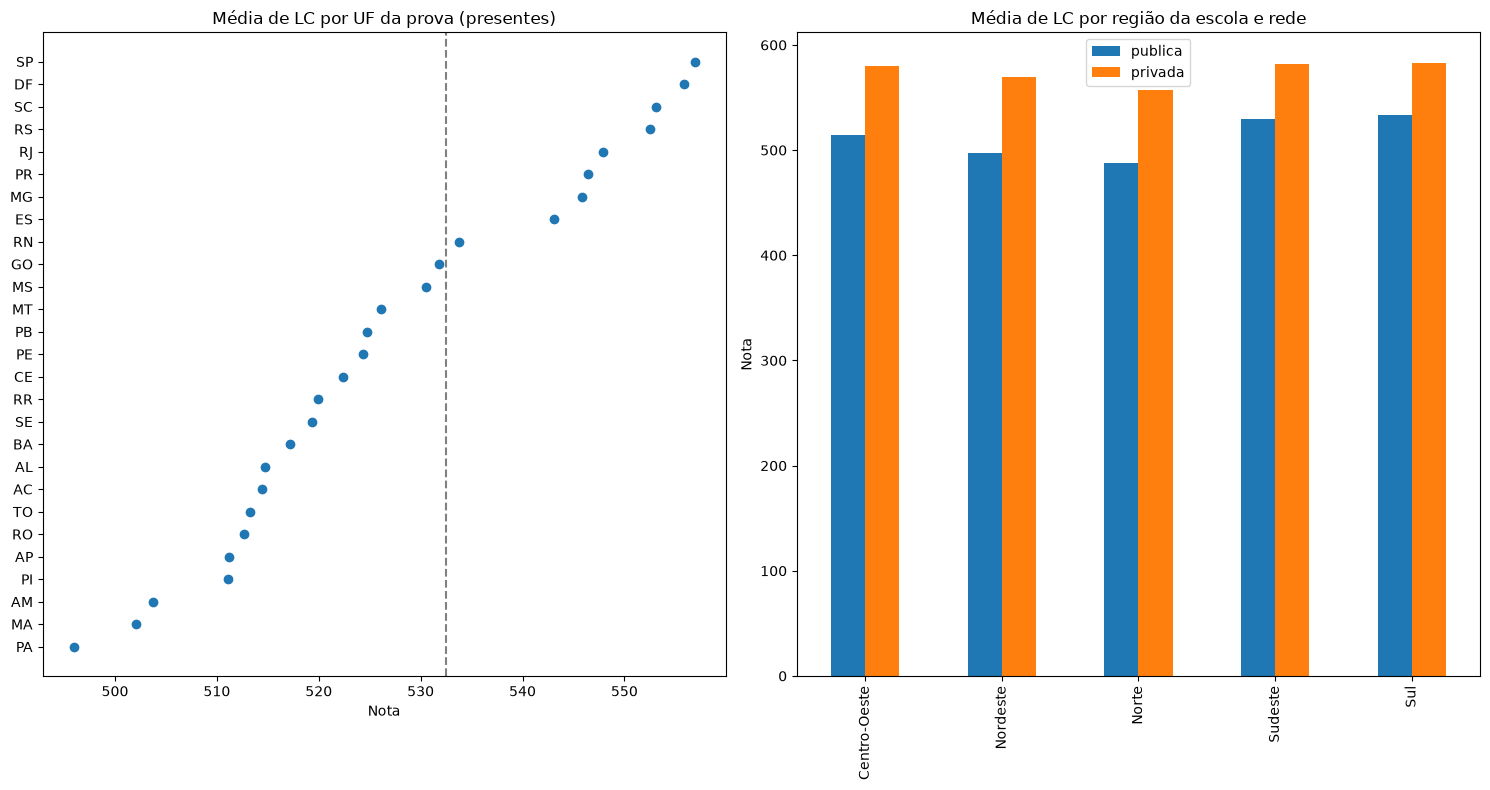

In [15]:
import matplotlib.pyplot as plt

for area in areas:
    notas = com_escola.loc[com_escola[f"TP_PRESENCA_{area}"] == 1, f"NU_NOTA_{area}"]
    print(area, "desvio-padrão:", round(notas.std(), 1))

Path("../images").mkdir(exist_ok=True)

fig, eixos = plt.subplots(1, 2, figsize=(15, 8))

# Gráfico 1: qual UF tem a maior média de LC?
ordem = medias_uf["LC"].sort_values()
eixos[0].scatter(ordem.values, ordem.index)
media_nacional_lc = df.loc[df["TP_PRESENCA_LC"] == 1, "NU_NOTA_LC"].mean()
eixos[0].axvline(media_nacional_lc, linestyle="--", color="gray")
eixos[0].set_title("Média de LC por UF da prova (presentes)")
eixos[0].set_xlabel("Nota")

# Gráfico 2: a diferença entre redes se repete em todas as regiões?
reg = pivo(com_escola, "REGIAO_ESC", "LC")[["publica", "privada"]]
reg.plot(kind="bar", ax=eixos[1])
eixos[1].set_title("Média de LC por região da escola e rede")
eixos[1].set_ylabel("Nota")
eixos[1].set_xlabel("")

plt.tight_layout()
fig.savefig("../images/lc_estados_e_redes.png", dpi=150)
plt.show()

In [16]:
for numero in [7, 8]:
    print("=== página", numero)
    print(read.pages[numero - 1].extract_text())

=== página 7
7  
  
  
  
  
3- MICRODADOS DO ENEM   
  
Para atender à demanda dos usuários por informações específicas, os microdados do Enem 2025 foram 
organizados em três bases de dados: PARTICIPANTES_2025.csv, RESULTADOS_2025.csv e 
ITENS_PROVA_2025.csv. O arquivo PARTICIPANTES_2025.csv reúne, em uma única base, as 
informações de caracterização dos participantes e as respostas ao questionário socioeconômico, com 
o objetivo de facilitar a utilização dos resultados e das informações disponibilizadas sobre os 
participantes do Enem. O arquivo RESULTADOS_2025.csv reúne informações sobre a escola de 
conclusão do ensino médio, as provas, os gabaritos e as notas dos participantes. Já o arquivo 
ITENS_PROVA_2025.csv disponibiliza informações detalhadas sobre os itens das provas. O 
Dicionário de Dados contém a descrição das variáveis presentes em cada uma dessas bases. Ressalta-
se que os arquivos PARTICIPANTES_2025.csv e RESULTADOS_2025.csv não possuem chave de 
ligação em comum. Des

In [17]:
reg = pivo(com_escola, "REGIAO_ESC", "LC")[["publica", "privada"]]
reg.columns = ["Public", "Private"]
reg.plot(kind="bar", ax=eixos[1])
eixos[1].set_title("Mean LC score by school region and school type\n(only participants with school information)")
eixos[1].set_ylabel("Score")
eixos[1].set_xlabel("")
eixos[1].legend(loc="lower right")
eixos[1].tick_params(axis="x", rotation=0)

### Chart notes

**Mean LC score by state:** the eight highest means (SP, DF, SC, RS, RJ, PR, MG, ES) are separated from the rest by a gap of about 9 points; almost all Northeast and North states fall below the national mean. The spread between the highest and the lowest state (about 61 points) is smaller than the standard deviation of individual scores (about 73 points).

**Public vs. private (LC):** the private-school mean is higher in every region, with the smallest gaps in the South and Southeast. This covers only participants with school information, which the INEP read-me says was obtained by linking to the 2025 School Census; it may not represent all participants.

**Spread by area:** score dispersion differs by area (standard deviation: CN 77, CH 85, LC 73, MT 126), so gaps measured in points are not directly comparable across areas.

**School information.** According to the INEP read-me (pp. 7–8), the school code comes from the 2025 School Census, linked by CPF, restricted to enrollments in final-year stages of high school (3rd/4th year, integrated technical, "normal", non-graded and EJA). Participants with no such match have no school information (about 61% of present participants). Public vs. private comparisons therefore apply only to participants matched to a final-year enrollment, not to all participants. For students with more than one enrollment, INEP gave priority to public-network, regular-education, longer-hours and same-municipality enrollments. INEP advises against using these data to rank schools; this project reports only aggregates by state, region and school type. The questionnaire lives in a file that cannot be linked, so socioeconomic status cannot be controlled for.

**Geography.** Municipality of residence was removed from the 2025 microdata, so state means refer to the state where the exam was taken (`SG_UF_PROVA`).

**Removed records.** INEP removed participants of a few exam versions with very few takers, to prevent identification.

In [18]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
df.to_parquet("../data/processed/results_2025_selected_columns.parquet")
com_escola.to_parquet("../data/processed/results_2025_with_school.parquet")

In [19]:
por_uf_lc = pivo(com_escola, "SG_UF_ESC", "LC")

for corte in [500, 1000, 2000]:
    selecao = por_uf_lc[por_uf_lc["n_priv"] >= corte].sort_values("gap")
    print(
        "corte", corte, "| estados:", len(selecao),
        "| menor gap:", selecao.index[0], round(selecao["gap"].iloc[0], 1),
        "| maior gap:", selecao.index[-1], round(selecao["gap"].iloc[-1], 1),
    )

corte 500 | estados: 26 | menor gap: SP 46.6 | maior gap: AM 88.4
corte 1000 | estados: 23 | menor gap: SP 46.6 | maior gap: AM 88.4
corte 2000 | estados: 22 | menor gap: SP 46.6 | maior gap: AM 88.4


In [20]:
nacional = {}
for area in areas:
    notas = df.loc[df[f"TP_PRESENCA_{area}"] == 1, f"NU_NOTA_{area}"]
    nacional[area] = (notas.mean(), notas.std())

z = pd.DataFrame(index=medias_uf.index)
for area in areas:
    media, desvio = nacional[area]
    z[area] = (medias_uf[area] - media) / desvio

z["amplitude"] = z[areas].max(axis=1) - z[areas].min(axis=1)
print(z.round(2).sort_values("amplitude").to_string())

               CN    CH    LC    MT  amplitude
SG_UF_PROVA                                   
MT          -0.05 -0.07 -0.09 -0.09       0.04
GO           0.03 -0.00 -0.01  0.01       0.04
ES           0.16  0.17  0.15  0.20       0.05
MS           0.00 -0.02 -0.03 -0.05       0.05
TO          -0.22 -0.23 -0.27 -0.26       0.05
PR           0.14  0.16  0.20  0.19       0.05
MG           0.16  0.19  0.19  0.22       0.07
CE          -0.10 -0.13 -0.14 -0.07       0.07
SC           0.22  0.26  0.29  0.26       0.07
PE          -0.06 -0.14 -0.11 -0.07       0.08
AL          -0.17 -0.23 -0.25 -0.22       0.08
MA          -0.34 -0.35 -0.43 -0.39       0.08
PI          -0.22 -0.28 -0.30 -0.22       0.08
PB          -0.03 -0.10 -0.11 -0.11       0.09
RN           0.07  0.00  0.02 -0.03       0.10
RO          -0.18 -0.23 -0.28 -0.25       0.10
SE          -0.10 -0.16 -0.18 -0.20       0.10
BA          -0.15 -0.21 -0.22 -0.26       0.11
DF           0.25  0.28  0.33  0.22       0.11
RJ           

In [21]:
guia = list(pasta.glob("*/Entenda_a_Sua_Nota_no_Enem_Guia_do_Participante.pdf"))
leitor = PdfReader(guia[0])
for i, pagina in enumerate(leitor.pages):
    texto = pagina.extract_text() or ""
    for linha in texto.split("\n"):
        if "escala" in linha.lower() or "compar" in linha.lower():
            print(i + 1, "|", linha)

5 |  1.2 Posicionando sua nota na escala (régua) ...................................................................................... 9
8 | em uma métrica (escala) criada pelo Inep especialmente para o Enem, com o objetivo de medir 
9 | Medir é avaliar algo por meio de um instrumento de medida e comparar com um padrão. 
9 | de medida é a prova, e o padrão dessa medida é a escala, construída por meio do modelo de TRI 
10 | quanto maior seu valor, mais difícil é a questão. Ele é expresso    n a mesma escala 
11 | 1.2 POSICIONANDO SUA NOTA NA ESCALA (RÉGUA)
11 | escala (régua), permitindo, desse modo, sua interpretação pedagógica. O posicionamento de cada 
11 | questão nos níveis da escala se dá por meio de critérios probabilísticos, os quais garantem que 
11 | O Inep criou uma escala para cada área do conhecimento. Isso quer dizer que quatro notas 
11 | são calculadas, sendo que cada escala depende de dois valores:
12 | ILUSTRAÇÃO DA ESCALA DE PROFICIÊNCIA DO ENEM
12 | A escala tem uma

### Robustness checks

**Minimum private-school sample per state (LC gap):** thresholds of 500, 1,000 and 2,000 private-school students leave 26, 23 and 22 states; the states with the smallest (SP) and largest (AM) public–private gaps do not change. The MT ranking was not tested.

**State profile across areas (z-scores):** state means were standardized against the national mean and the individual-level standard deviation of each area. Scores are consistently above or below the national mean across the four areas; the largest spread between areas within a state is about 0.2 standard deviations (AP). "Balanced" here means similar across areas, not high.

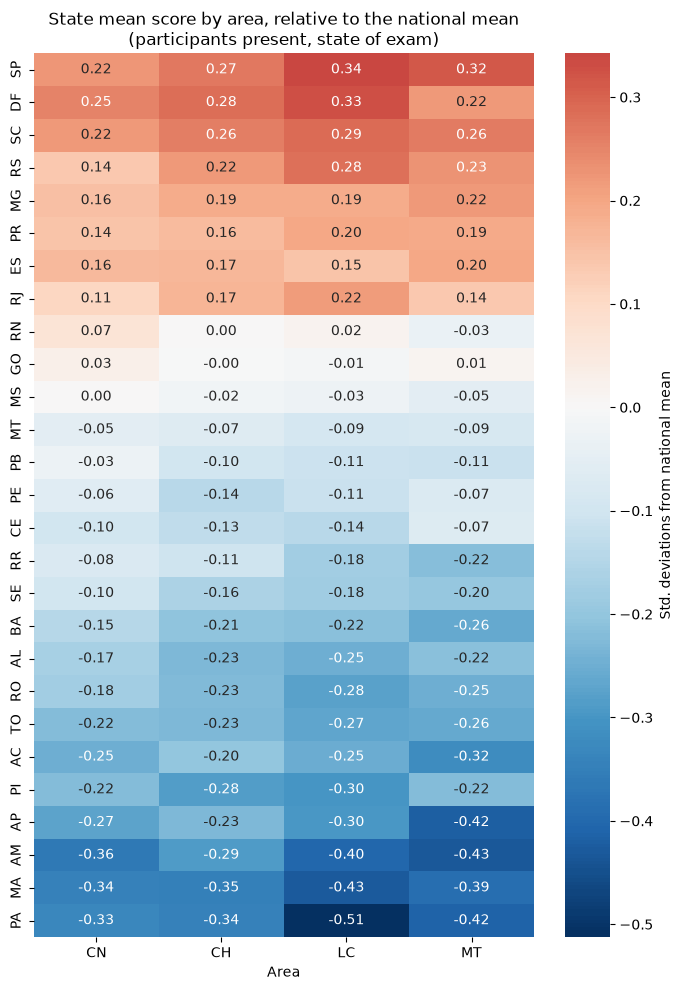

In [22]:
import seaborn as sns

ordem = z[areas].mean(axis=1).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(
    z.loc[ordem, areas],
    annot=True, fmt=".2f",
    cmap="RdBu_r", center=0,
    cbar_kws={"label": "Std. deviations from national mean"},
    ax=ax,
)
ax.set_title("State mean score by area, relative to the national mean\n(participants present, state of exam)")
ax.set_xlabel("Area")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig("../images/heatmap_state_area_z.png", dpi=150)
plt.show()

LC média: 532.5 | mediana: 538.8


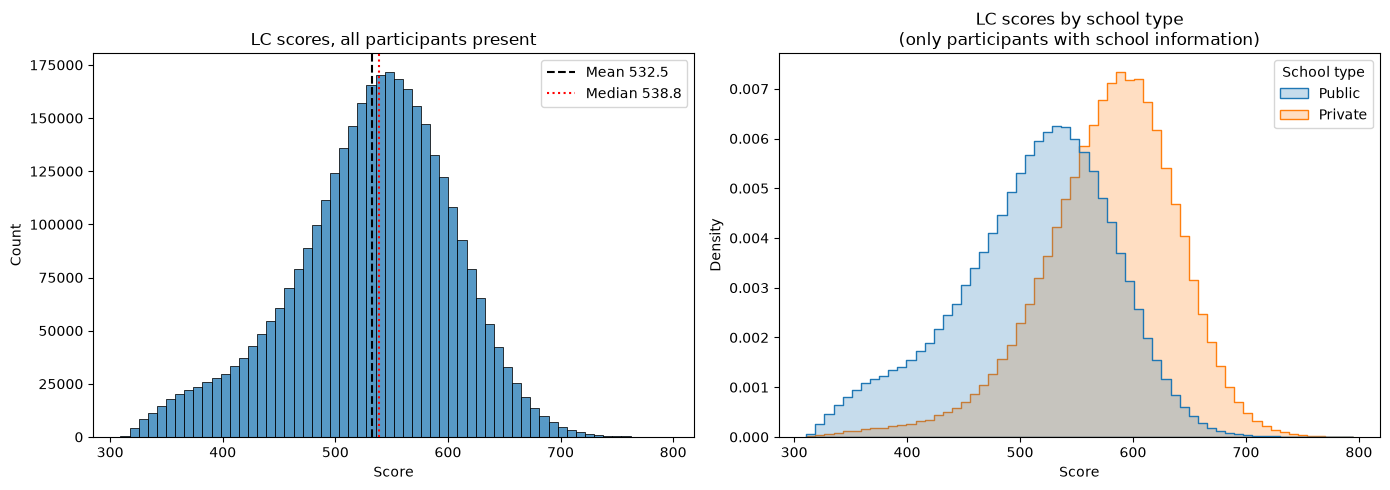

In [23]:
lc = df.loc[df["TP_PRESENCA_LC"] == 1, "NU_NOTA_LC"]
media, mediana = lc.mean(), lc.median()
print("LC média:", round(media, 1), "| mediana:", round(mediana, 1))

lc_escola = com_escola[com_escola["TP_PRESENCA_LC"] == 1].copy()
lc_escola["School type"] = lc_escola["REDE"].map({"Pública": "Public", "Privada": "Private"})

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(lc, bins=60, ax=eixos[0])
eixos[0].axvline(media, linestyle="--", color="black", label=f"Mean {media:.1f}")
eixos[0].axvline(mediana, linestyle=":", color="red", label=f"Median {mediana:.1f}")
eixos[0].set_title("LC scores, all participants present")
eixos[0].set_xlabel("Score")
eixos[0].legend()

sns.histplot(
    data=lc_escola, x="NU_NOTA_LC", hue="School type",
    bins=60, stat="density", common_norm=False, element="step", ax=eixos[1],
)
eixos[1].set_title("LC scores by school type\n(only participants with school information)")
eixos[1].set_xlabel("Score")

plt.tight_layout()
fig.savefig("../images/lc_distributions.png", dpi=150)
plt.show()

In [24]:

for area in areas:
    notas = df.loc[df[f"TP_PRESENCA_{area}"] == 1, f"NU_NOTA_{area}"]
    print(
        area,
        "| notas == 0:", (notas == 0).sum(),
        "| menor nota > 0:", notas[notas > 0].min(),
        "| média sem zeros:", round(notas[notas > 0].mean(), 2),
        "| média com zeros:", round(notas.mean(), 2),
    )
print()


pub = lc_escola.loc[lc_escola["School type"] == "Public", "NU_NOTA_LC"]
priv = lc_escola.loc[lc_escola["School type"] == "Private", "NU_NOTA_LC"]
print("Percentis 10/25/50/75/90, pública: ", pub.quantile([.1, .25, .5, .75, .9]).round(0).tolist())
print("Percentis 10/25/50/75/90, privada: ", priv.quantile([.1, .25, .5, .75, .9]).round(0).tolist())
print("% de alunos da pública acima da mediana da privada:", round((pub > priv.median()).mean() * 100, 1))
print("% de alunos da privada abaixo da mediana da pública:", round((priv < pub.median()).mean() * 100, 1))

CN | notas == 0: 0 | menor nota > 0: 308.6 | média sem zeros: 500.09 | média com zeros: 500.09
CH | notas == 0: 0 | menor nota > 0: 320.8 | média sem zeros: 512.54 | média com zeros: 512.54
LC | notas == 0: 0 | menor nota > 0: 309.2 | média sem zeros: 532.49 | média com zeros: 532.49
MT | notas == 0: 0 | menor nota > 0: 312.6 | média sem zeros: 520.12 | média com zeros: 520.12

Percentis 10/25/50/75/90, pública:  [414.0, 470.0, 520.0, 561.0, 595.0]
Percentis 10/25/50/75/90, privada:  [501.0, 543.0, 584.0, 619.0, 649.0]
% de alunos da pública acima da mediana da privada: 14.1
% de alunos da privada abaixo da mediana da pública: 15.4


### Comparing areas

According to the INEP participant guide (pp. 11, 25), each knowledge area has its own scale, so raw scores of different areas are not directly comparable. In this project, comparisons are made *within* an area (between states, regions and school types). Standardized measures (z-scores, differences in standard deviations) are used only to describe relative position within each area, not to claim that areas measure the same thing.

### Distribution notes (LC)

LC scores are left-skewed (mean 532.1, median 538.8). Public and private school distributions overlap substantially: the mean gap (65.6 points, about 0.9 standard deviations) does not mean that every private-school student outscores every public-school student. A small group of LC scores equal to zero was found and is being investigated.

In [25]:
zeros_ch = df[(df["TP_PRESENCA_CH"] == 1) & (df["NU_NOTA_CH"] == 0)]
print("Zeros em CH:", len(zeros_ch))
print("Desses, também zero em LC:", (zeros_ch["NU_NOTA_LC"] == 0).sum())
print()

print("Status da redação desses participantes:")
print(zeros_ch["TP_STATUS_REDACAO"].value_counts(dropna=False).sort_index())
print()

print("Presença deles em CN:")
print(zeros_ch["TP_PRESENCA_CN"].value_counts().sort_index())
print()

presentes_ch = df[df["TP_PRESENCA_CH"] == 1]
zeros_por_uf = presentes_ch.groupby("SG_UF_PROVA")["NU_NOTA_CH"].apply(lambda s: (s == 0).mean() * 100)
print("% de zeros em CH entre os presentes, 10 maiores estados:")
print(zeros_por_uf.round(2).sort_values(ascending=False).head(10))

Zeros em CH: 0
Desses, também zero em LC: 0

Status da redação desses participantes:
Series([], Name: count, dtype: int64)

Presença deles em CN:
Series([], Name: count, dtype: int64)

% de zeros em CH entre os presentes, 10 maiores estados:
SG_UF_PROVA
AC    0.0
AL    0.0
AM    0.0
AP    0.0
BA    0.0
CE    0.0
DF    0.0
ES    0.0
GO    0.0
MA    0.0
Name: NU_NOTA_CH, dtype: float64


In [26]:
edital = list(pasta.glob("*/Edital_ENEM_2025.pdf"))
leitor_edital = PdfReader(edital[0])
for i, pagina in enumerate(leitor_edital.pages):
    texto = pagina.extract_text() or ""
    for linha in texto.split("\n"):
        if "nota zero" in linha.lower() or "atribu" in linha.lower() and "zero" in linha.lower():
            print(i + 1, "|", linha)

In [27]:
colunas_resp = ["TP_PRESENCA_CH", "NU_NOTA_CH", "TX_RESPOSTAS_CH"]
pedacos = []

for pedaco in pd.read_csv(
    arquivos["resultados"], sep=";", encoding="latin-1",
    usecols=colunas_resp, chunksize=500_000,
):
    zeros = pedaco[(pedaco["TP_PRESENCA_CH"] == 1) & (pedaco["NU_NOTA_CH"] == 0)]
    pedacos.append(zeros)

zeros_resp = pd.concat(pedacos)
print("Zeros em CH:", len(zeros_resp))
print("Sem texto de respostas:", zeros_resp["TX_RESPOSTAS_CH"].isna().sum())

respostas = zeros_resp["TX_RESPOSTAS_CH"].dropna().str[:45]
print(respostas.head(8).tolist())

em_branco = respostas.str.count(r"\.")
print("Respostas em branco por participante:")
print(em_branco.describe().round(1))
print("Todas as 45 em branco:", (em_branco == 45).sum())

Zeros em CH: 9087
Sem texto de respostas: 0
['.............................................', '.............................................', '.............................................', '.............................................', '.............................................', '.............................................', '.............................................', '.............................................']
Respostas em branco por participante:
count    9087.0
mean       45.0
std         0.0
min        45.0
25%        45.0
50%        45.0
75%        45.0
max        45.0
Name: TX_RESPOSTAS_CH, dtype: float64
Todas as 45 em branco: 9087


In [28]:
ch = df[df["TP_PRESENCA_CH"] == 1]
com_zero = ch.groupby("SG_UF_PROVA")["NU_NOTA_CH"].mean()
sem_zero = ch[ch["NU_NOTA_CH"] > 0].groupby("SG_UF_PROVA")["NU_NOTA_CH"].mean()

comparacao = pd.DataFrame({"com_zeros": com_zero, "sem_zeros": sem_zero})
comparacao["diferenca"] = comparacao["sem_zeros"] - comparacao["com_zeros"]
comparacao["posicao_com"] = comparacao["com_zeros"].rank(ascending=False)
comparacao["posicao_sem"] = comparacao["sem_zeros"].rank(ascending=False)
comparacao["mudanca"] = comparacao["posicao_com"] - comparacao["posicao_sem"]

print(comparacao.round(2).sort_values("com_zeros", ascending=False).to_string())

             com_zeros  sem_zeros  diferenca  posicao_com  posicao_sem  mudanca
SG_UF_PROVA                                                                    
DF              536.37     536.37        0.0          1.0          1.0      0.0
SP              535.27     535.27        0.0          2.0          2.0      0.0
SC              534.48     534.48        0.0          3.0          3.0      0.0
RS              531.22     531.22        0.0          4.0          4.0      0.0
MG              528.68     528.68        0.0          5.0          5.0      0.0
RJ              527.14     527.14        0.0          6.0          6.0      0.0
ES              526.92     526.92        0.0          7.0          7.0      0.0
PR              526.06     526.06        0.0          8.0          8.0      0.0
RN              512.58     512.58        0.0          9.0          9.0      0.0
GO              512.36     512.36        0.0         10.0         10.0      0.0
MS              511.17     511.17       

In [29]:
import geopandas as gpd

arquivos_shp = list(pasta.parent.glob("ibge_uf_2025/*.shp"))
print(arquivos_shp)

mapa = gpd.read_file(arquivos_shp[0])
print(len(mapa))
print(mapa.columns.tolist())
print(mapa.crs)

[WindowsPath('../data/raw/ibge_uf_2025/BR_UF_2025.shp')]
27
['CD_UF', 'NM_UF', 'SIGLA_UF', 'CD_REGIAO', 'NM_REGIAO', 'SIGLA_RG', 'AREA_KM2', 'geometry']
EPSG:4674


Estados sem média: 0


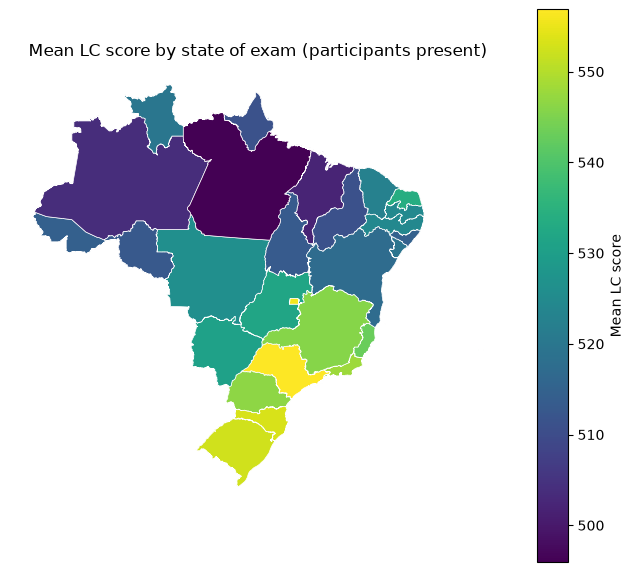

In [30]:
col_sigla = "SIGLA_UF"   # troque se a lista de colunas da célula A mostrar outro nome

mapa_lc = mapa.merge(medias_uf[["LC"]], left_on=col_sigla, right_index=True, how="left")
print("Estados sem média:", mapa_lc["LC"].isna().sum())

fig, ax = plt.subplots(figsize=(8, 8))
mapa_lc.plot(
    column="LC", cmap="viridis", legend=True,
    edgecolor="white", linewidth=0.5, ax=ax,
    legend_kwds={"label": "Mean LC score"},
)
ax.set_title("Mean LC score by state of exam (participants present)")
ax.set_axis_off()
fig.savefig("../images/map_lc_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

**Geographic data:** state boundaries are the IBGE territorial mesh (2025). The raw files are stored in `data/raw/ibge_uf_2025/` (not versioned); see the IBGE territorial meshes page to download them.

In [31]:
cols = []
for a in areas:
    cols += [f"TP_PRESENCA_{a}", f"NU_NOTA_{a}", f"TX_RESPOSTAS_{a}"]

contagem = {a: {"zeros": 0, "em_branco": 0, "ambos": 0} for a in areas}

for pedaco in pd.read_csv(
    arquivos["resultados"], sep=";", encoding="latin-1",
    usecols=cols, chunksize=500_000,
):
    for a in areas:
        presentes_a = pedaco[pedaco[f"TP_PRESENCA_{a}"] == 1]
        branco = presentes_a[f"TX_RESPOSTAS_{a}"].str[:45] == "." * 45
        zero = presentes_a[f"NU_NOTA_{a}"] == 0
        contagem[a]["zeros"] += int(zero.sum())
        contagem[a]["em_branco"] += int(branco.sum())
        contagem[a]["ambos"] += int((zero & branco).sum())

print(pd.DataFrame(contagem).T)

    zeros  em_branco  ambos
CN    775        775    775
CH   9087       9087   9087
LC   2361       2361   2361
MT    893        893    893


In [32]:
for a in areas:
    pres = f"TP_PRESENCA_{a}"
    nota = f"NU_NOTA_{a}"
    print(
        a,
        "| presença 3:", (df[pres] == 3).sum(),
        "| zeros restantes:", (df.loc[df[pres] == 1, nota] == 0).sum(),
    )

CN | presença 3: 775 | zeros restantes: 0
CH | presença 3: 9087 | zeros restantes: 0
LC | presença 3: 2361 | zeros restantes: 0
MT | presença 3: 893 | zeros restantes: 0


In [33]:
print("Médias nacionais por área:")
for a in areas:
    print(a, round(df.loc[df[f"TP_PRESENCA_{a}"] == 1, f"NU_NOTA_{a}"].mean(), 2))
print()

medias_uf = tabela_medias(df, "SG_UF_PROVA")
for a in areas:
    ordem = medias_uf[a].sort_values(ascending=False)
    print(a, "| maior:", ordem.index[0], round(ordem.iloc[0], 1),
          "| menor:", ordem.index[-1], round(ordem.iloc[-1], 1))
print()

medias_rede = tabela_medias(com_escola, "REDE")
diferenca = medias_rede.loc["Privada", areas] - medias_rede.loc["Pública", areas]
print("Privada menos pública:")
print(diferenca.round(1))

Médias nacionais por área:
CN 500.09
CH 512.54
LC 532.49
MT 520.12

CN | maior: DF 519.8 | menor: AM 471.7
CH | maior: DF 536.4 | menor: MA 482.9
LC | maior: SP 556.9 | menor: PA 496.0
MT | maior: SP 560.5 | menor: AM 464.7

Privada menos pública:
CN     75.0
CH     77.8
LC     65.5
MT    132.3
dtype: float64
